                               photos  samples  px_per_mm
split camera                                             
test  iPhone 14                    14        3       13.9
      iPhone 16                    21        7       19.5
train Motorola Edge                69       22        4.6
      Motorola Edge 60 Fusion       3        1       12.5
      Samsung A52                  55       22        4.6
train-like target: 4.597 px/mm
162 photos, 19 features in 71 s
Weibull representation floor (mean EMD to the 24 true curves): 7.65  « CV error → curve-family bias is negligible; the bottleneck is prediction, not representation)

── CROSS-PHONE CV (the selection gate) ──
baseline: dog5, mean,   a=1.0 (v1 replica)            50.67  (n=21)
dog5, median, a=1.0                                   52.50  (n=21)
dog5, mean,   a=0.5                                   51.23  (n=21)
dog5, mean,   a=2.0                                   50.59  (n=21)
dog5+gran,    median, a=1.0                        

config.json:   0%|          | 0.00/6.57k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

SAM on GPU

measuring 38 photos (expect 38: 35 test + 3 H374)


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


SAM done in 232 s
                          photos    A63    A20  cover  max_stone_mm
sample_id                                                          
HPC_Muenster_BS6_9_0-10m       5  0.249  0.715  0.822       103.818
HPC_Testfeld Lidl WHV          4  0.009  0.435  0.618        63.455
H374                           3  0.015  0.190  0.311        64.702
HPC_Audorfring                 5  0.000  0.061  0.158        42.069
HPC_Airbus BS10-4bis7          3  0.000  0.004  0.019        29.077
HPC_Kleinkummerfeld 2-3        3  0.000  0.002  0.005        21.540
HPC_Airbus BS12-5bis8          3  0.000  0.000  0.008        17.303
HPC_Kleinkummerfeld 2-2        3  0.000  0.000  0.006        15.118
HPC_Kleinkummerfeld 18-3       3  0.000  0.000  0.001         9.850
HPC_Airbus BS6-3               3  0.000  0.000  0.010        19.309
HPC_Kleinkummerfeld 9-4        3  0.000  0.000  0.003        17.507

k = (100 − F20_true(H374)) / (100·A20(H374)) = (100 − 76.49) / (100 · 0.190) = 1.238
k sensitivit

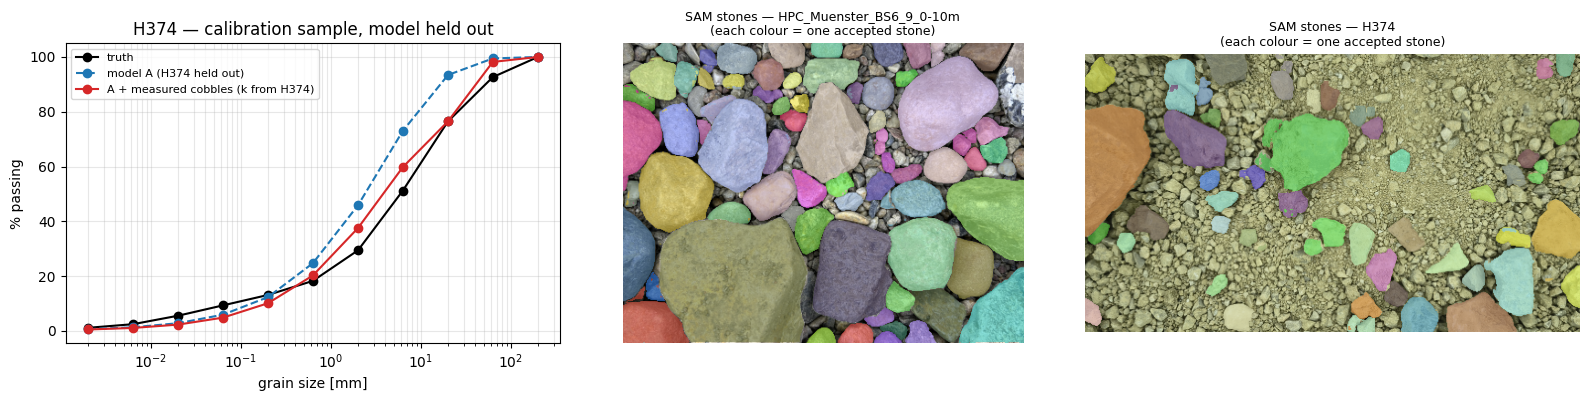


── PARAMETER PROVENANCE (for the write-up) ──
           parameter                                          value                                                                           origin
        common scale                                      4.5 px/mm       a priori: just below the coarsest training scale (~4.6) → pure downscaling
         centre crop                                           50 %                                       a priori: excludes tray edges / vignetting
           DoG bands                      0.5–8 mm, half log-decade                 a priori: one band per metric interval in the visible size range
train-like threshold                                      6.0 px/mm                  data: separates the two resolution clusters (4.6 vs 12.5 px/mm)
    JPEG degradation                       training q-tables, 4:2:0                                          data: copied from a real training photo
 model configuration {'feats': 'dog5', 'agg': 'mean', 'alph

In [1]:
# %% [0] ═══════════════════════════════════════════════════════════════════
# SOIL GRAIN SIZE FROM PHOTOS — v4 "defensible"
# ─────────────────────────────────────────────────────────────────────────
# METHOD (the one-paragraph version for the viva):
#   1. DOMAIN ALIGNMENT — test photos (iPhone, 14–20 px/mm, JPEG q≈94) are
#      degraded to the training imaging condition (downscale to the median
#      training scale, re-encode with the JPEG quantisation tables of a real
#      training photo). We degrade the sharp test images rather than "repair"
#      the degraded training ones: degradation is a known operator, its
#      inverse is not.
#   2. PHYSICAL SCALING — every photo is resampled to a common 4.5 px/mm
#      (from ppm.csv × aspect correction), so that all image-space scales
#      correspond to the same physical length in millimetres.
#   3. FEATURES — energies of Difference-of-Gaussian bands at 0.5–8 mm
#      (one band per half log-decade: an "image-domain sieve"); granulometry
#      and FFT band features are computed only for the ablation study.
#   4. REGRESSION — Ridge predicts (ln b, c) of a Weibull grading curve
#      F(d) = 100·(1 − exp(−(d/b)^c)). Two parameters, shape fixed by
#      physics, fitted to the 24 training curves by minimising the
#      competition metric itself. Per-photo curves are aggregated per sample.
#   5. COBBLE BRANCH — no training sample can teach "30% of the mass is
#      > 63 mm", but stones are directly visible. SAM (pretrained, frozen,
#      zero-shot — used as a measuring instrument, not trained) segments
#      stones at 2 px/mm; the surface area share of stones with long axis
#      > 20 / > 63 mm is converted to a mass share with ONE global factor
#      k, calibrated on H374 — the only training sample with full-res
#      photos and stones (true 23.5% coarser than 20 mm, measured A20).
#   6. MODEL SELECTION — every learned choice is gated on CROSS-PHONE CV
#      (train Motorola → validate Samsung, and back), which simulates the
#      actual train/test domain shift. Site-grouped LOSO is printed for
#      reference only: it does not contain the phone shift and is NOT used
#      for selection.
# METRIC — log-weighted EMD. The 11 support points are half a log-decade
#      apart, so every interval weighs ≈ 0.5 and EMD ≈ 0.5·Σ|ΔF| over the
#      first 10 points: an L1 metric. Consequently we aggregate with
#      median-compatible machinery and enforce monotonicity by L1 (PAVA)
#      projection. Verified in code: Σ widths = 5.0 ⇒ max EMD = 500.
# DETERMINISM — no random numbers occur anywhere in the pipeline (Ridge,
#      PAVA, Weibull fitting, SAM's point grid are all deterministic).
#      Re-running this notebook reproduces submission.csv exactly (on the
#      same GPU type). Plot colours use a fixed rng(0).
# ═════════════════════════════════════════════════════════════════════════
import io, re, time, unicodedata
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from scipy.optimize import minimize
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

IS_KAGGLE = Path("/kaggle/input").exists()
INPUT_DIR = sorted(Path("/kaggle/input").glob("**/Training_labels_updated.csv"))[0].parent if IS_KAGGLE else Path("input")
OUTPUT_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SIZES = [0.002, 0.0063, 0.02, 0.063, 0.2, 0.63, 2, 6.3, 20, 63, 200]
SIZE_COLS = ["0.002", "0.0063", "0.02", "0.063", "0.2", "0.63", "2", "6.3", "20", "63", "200"]
W_EMD = np.diff(np.log10(SIZES))
assert abs(W_EMD.sum() * 100 - 500.0) < 1e-9          # metric identity: max EMD = 500 ✓
CAM_EDGE, CAM_A52 = "Motorola Edge", "Samsung A52"

CFG = {
    # ── image path (all values fixed a priori, before any LB feedback) ──
    "target_ppm": 4.5,        # just below the coarsest training scale (~4.6 px/mm) → everything is downscaled
    "crop_frac": 0.5,         # centre crop: excludes tray edges and vignetting
    "dog_sigmas_mm": [0.25, 0.5, 1.0, 2.0, 4.0, 8.0],   # half log-decade apart → 5 bands = "image sieve"
    "gran_scales_mm": [0.5, 1.0, 2.0, 4.0, 8.0, 16.0],  # ablation-only
    "fft_bands_mm": [(0.5, 0.7), (0.7, 1.4), (1.4, 2.8)],  # ablation-only
    "train_like_above_ppm": 6.0,   # data-derived: separates the two resolution clusters (4.6 vs 12.5 px/mm)
    # ── label machinery ──
    "weights_group": {"gravel": 0.2, "non_gravel": 0.8},   # CV weighting prior: expected test composition
    "grid_lnb": [-6.0, 4.0, 41], "grid_c": [0.1, 2.0, 39], "c_floor": 0.02,
    # ── SAM stone measurement (all fixed a priori, before any LB feedback) ──
    "sam_model": "facebook/sam-vit-base", "sam_min_ppm": 12.0, "work_ppm": 2.0, "work_crop": 0.12,
    "pred_iou_thresh": 0.86, "stability_score_thresh": 0.9, "points_per_batch": 64,
    "overlap_drop": 0.5, "min_fill": 0.35, "min_side_mm": 8.0, "max_area_frac": 0.5,
    "apply_if_A63_ge": 0.02,  # redraw only when cobbles are clearly present (≥2% of the area)
    # ── model selection ──
    "select_margin": 1.0,     # parsimony: switch away from the v1 baseline only if CV improves by > 1 EMD
}

# %% [1] ── index the photos ────────────────────────────────────────────────
CAMERA_RE = re.compile(r"^(Motorola_Edge_60_fusion|Motorola_Edge|Samsung_A52|iPhone_?14|iPhone_?16)_(.+?)(?:_\d+| \(\d+\))?$")
CAMERA_KEY = {"Motorola_Edge_60_fusion": "Motorola Edge 60 Fusion", "Motorola_Edge": CAM_EDGE, "Samsung_A52": CAM_A52,
              "iPhone14": "iPhone 14", "iPhone_14": "iPhone 14", "iPhone16": "iPhone 16", "iPhone_16": "iPhone 16"}

def normalize_id(raw: str) -> str:
    s = unicodedata.normalize("NFC", raw).replace("ü", "ue").replace("ö", "oe").replace("ä", "ae")
    return s.replace(",", "_")

labels = pd.read_csv(INPUT_DIR / "Training_labels_updated.csv", dtype={"sample_id": str}).set_index("sample_id")
sample_sub = pd.read_csv(INPUT_DIR / "sample_submission.csv", dtype={"sample_id": str})
ppm_tab = pd.read_csv(INPUT_DIR / "ppm_updated.csv").set_index("phone")

rows = []
for split, pattern in [("train", "Training-All_Photos*"), ("test", "Test_All_Photos*")]:
    for p in sorted(INPUT_DIR.glob(f"{pattern}/**/*")):
        if p.suffix.lower() not in {".jpg", ".jpeg"}:
            continue
        m = CAMERA_RE.match(unicodedata.normalize("NFC", p.stem))
        if m is None:
            raise ValueError(f"unexpected file name: {p.name}")
        with Image.open(p) as im:
            w, h = im.size
        rows.append({"split": split, "path": p, "camera": CAMERA_KEY[m.group(1)],
                     "sample_id": normalize_id(m.group(2)), "w": w, "h": h})
photos = pd.DataFrame(rows)
photos["ppm_eff"] = [ppm_tab.loc[c, "ppm"] * max(w, h) / ppm_tab.loc[c, "width"]   # aspect-corrected table PPM
                     for c, w, h in zip(photos.camera, photos.w, photos.h, strict=True)]
assert sorted(set(photos.query("split == 'train'").sample_id)) == sorted(labels.index)
assert set(photos.query("split == 'test'").sample_id) == set(sample_sub.sample_id)

lab = labels.copy()
lab["type"] = np.select([lab["0.063"] >= 40, (lab["63"] - lab["2"]) >= 40], ["fine", "gravel"], "sand")
lab["group"] = np.where(lab["type"] == "gravel", "gravel", "non_gravel")
print(photos.groupby(["split", "camera"]).agg(photos=("path", "size"), samples=("sample_id", "nunique"),
                                              px_per_mm=("ppm_eff", "median")).round(1))

# %% [2] ── features: train-like degradation → common physical scale ────────
_train_small = photos[(photos.split == "train") & (photos.ppm_eff <= CFG["train_like_above_ppm"])]
TRAIN_LIKE_PPM = float(_train_small.ppm_eff.median())                          # data-derived degradation target
TRAIN_QTABLES = Image.open(sorted(_train_small[_train_small.camera == CAM_A52].path)[0]).quantization
print(f"train-like target: {TRAIN_LIKE_PPM:.3f} px/mm")

def to_train_like(rgb, ppm_eff):
    """Push a sharp test photo through the training imaging condition:
    downscale to the median training scale, re-encode with the training JPEG
    quantisation tables (4:2:0 subsampling)."""
    f = TRAIN_LIKE_PPM / ppm_eff
    small = cv2.resize(rgb, (round(rgb.shape[1] * f), round(rgb.shape[0] * f)), interpolation=cv2.INTER_AREA)
    buf = io.BytesIO()
    Image.fromarray(small).save(buf, format="JPEG", qtables=TRAIN_QTABLES, subsampling=2)
    return np.asarray(Image.open(io.BytesIO(buf.getvalue())).convert("RGB")), TRAIN_LIKE_PPM

def load_gray(path, ppm_eff):
    """EXIF rotation → train-like path if sharp → grayscale → landscape →
    4.5 px/mm (physical scale!) → 50% centre crop."""
    im = ImageOps.exif_transpose(Image.open(path))
    if ppm_eff > CFG["train_like_above_ppm"]:
        rgb, ppm_eff = to_train_like(np.asarray(im.convert("RGB")), ppm_eff)
        im = Image.fromarray(rgb)
    a = np.asarray(im.convert("L"))
    if a.shape[0] > a.shape[1]:
        a = np.ascontiguousarray(np.rot90(a))       # top-down shots: orientation carries no information
    f = CFG["target_ppm"] / ppm_eff
    a = cv2.resize(a, (round(a.shape[1] * f), round(a.shape[0] * f)), interpolation=cv2.INTER_AREA)
    h, w = a.shape
    ch, cw = int(h * CFG["crop_frac"]), int(w * CFG["crop_frac"])
    return a[(h - ch) // 2:(h - ch) // 2 + ch, (w - cw) // 2:(w - cw) // 2 + cw].astype(np.float32)

def dog_features(g):
    """Energy of each DoG band, normalised by image contrast (log). The image-domain sieve."""
    blurs = [cv2.GaussianBlur(g, (0, 0), s * CFG["target_ppm"]) for s in CFG["dog_sigmas_mm"]]
    sd = float(g.std()) + 1e-6
    return {f"dog_{s}mm": float(np.log(np.std(blurs[k - 1] - blurs[k]) / sd + 1e-6))
            for k, s in enumerate(CFG["dog_sigmas_mm"]) if k > 0}

def _morph_mean(g, s_mm, op):
    """Mean intensity after morphological opening/closing at physical scale s_mm
    (pyramid trick: large structuring elements applied on a downscaled image)."""
    r = max(s_mm * CFG["target_ppm"], 1.5)
    if r <= 24:
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * int(round(r)) + 1,) * 2)
        return float(cv2.morphologyEx(g, op, k).mean())
    f = r / 24.0
    small = cv2.resize(g, (max(int(round(g.shape[1] / f)), 60), max(int(round(g.shape[0] / f)), 60)),
                       interpolation=cv2.INTER_AREA)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (49, 49))
    return float(cv2.morphologyEx(small, op, k).mean())

def gran_features(g):
    """Matheron granulometry: change of mean intensity between successive opening
    (bright grains) / closing (dark pores) scales — a second image-domain sieve."""
    sd = float(g.std()) + 1e-6
    o = [_morph_mean(g, s, cv2.MORPH_OPEN) for s in CFG["gran_scales_mm"]]
    c = [_morph_mean(g, s, cv2.MORPH_CLOSE) for s in CFG["gran_scales_mm"]]
    out = {}
    for k in range(len(CFG["gran_scales_mm"]) - 1):
        s = CFG["gran_scales_mm"][k + 1]
        out[f"open_{s}mm"] = float(np.log(max(o[k] - o[k + 1], 1e-3) / sd + 1e-9))
        out[f"close_{s}mm"] = float(np.log(max(c[k + 1] - c[k], 1e-3) / sd + 1e-9))
    return out

def fft_features(g):
    """Radial power-spectrum energies in physical wavelength bands + spectral slope."""
    a = g - float(g.mean()); h, w = a.shape
    win = np.hanning(h)[:, None] * np.hanning(w)[None, :]
    F = np.fft.rfft2((a * win).astype(np.float32))
    p = F.real ** 2 + F.imag ** 2
    fy = np.fft.fftfreq(h)[:, None] * CFG["target_ppm"]
    fx = np.fft.rfftfreq(w)[None, :] * CFG["target_ppm"]
    fr = np.sqrt(fy ** 2 + fx ** 2)
    tot = float(p[fr > 0].mean()) + 1e-12
    out = {}
    for lo, hi in CFG["fft_bands_mm"]:
        m = (fr > 1.0 / hi) & (fr <= 1.0 / lo)
        out[f"fft_{lo}-{hi}mm"] = float(np.log(p[m].mean() / tot + 1e-12)) if m.any() else -12.0
    m = (fr > 0.33) & (fr < 2.1)
    x, y = np.log10(fr[m]).ravel(), np.log10(p[m].ravel() + 1e-12)
    out["fft_slope"] = float(np.polyfit(x, y, 1)[0]) if m.sum() > 20 else 0.0
    return out

t0 = time.time()
feats = pd.DataFrame([{**dog_features(g), **gran_features(g), **fft_features(g)}
                      for g in (load_gray(p, e) for p, e in zip(photos.path, photos.ppm_eff, strict=True))],
                     index=photos.index)
photos = photos.join(feats)
FEATS_DOG5 = [f"dog_{s}mm" for s in [0.5, 1.0, 2.0, 4.0, 8.0]]                 # v1 baseline feature set
FEATS_GRAN = [c for c in feats.columns if c.startswith(("open_", "close_"))]
FEATS_FFT  = [c for c in feats.columns if c.startswith("fft_")]
FEAT_SETS = {"dog5": FEATS_DOG5, "dog5+gran": FEATS_DOG5 + FEATS_GRAN,
             "dog5+fft": FEATS_DOG5 + FEATS_FFT, "dog5+gran+fft": FEATS_DOG5 + FEATS_GRAN + FEATS_FFT}
print(f"{len(photos)} photos, {len(feats.columns)} features in {time.time() - t0:.0f} s")

# %% [3] ── labels: EMD-fitted Weibull parameters (per-sample ⇒ no leakage) ─
_LOG_SIZES = np.log(np.asarray(SIZES, dtype=float))

def emd(y_true, y_pred):
    """Competition metric per sample: Σ |ΔF| × log10 interval width (first 10 points)."""
    return (np.abs(np.asarray(y_true)[..., :10] - np.asarray(y_pred)[..., :10]) * W_EMD).sum(-1)

def weibull_curve(lnb, c):
    lnb = np.asarray(lnb, dtype=float)[..., None]
    c = np.maximum(np.asarray(c, dtype=float), CFG["c_floor"])[..., None]
    return 100.0 * (1.0 - np.exp(-np.exp(c * (_LOG_SIZES - lnb))))

def fit_weibull_label(y):
    """Fit (ln b, c) to ONE true curve by minimising the competition metric
    (grid start → Nelder–Mead). Uses only that sample's own label."""
    g_lnb = np.linspace(CFG["grid_lnb"][0], CFG["grid_lnb"][1], int(CFG["grid_lnb"][2]))
    g_c = np.linspace(CFG["grid_c"][0], CFG["grid_c"][1], int(CFG["grid_c"][2]))
    L, C = np.meshgrid(g_lnb, g_c, indexing="ij")
    e = emd(y, weibull_curve(L.ravel(), C.ravel())).reshape(L.shape)
    k = np.unravel_index(int(np.argmin(e)), e.shape)
    x0 = np.array([L[k], C[k]])
    res = minimize(lambda x: float(emd(y, weibull_curve(x[0], x[1]))), x0, method="Nelder-Mead",
                   options={"xatol": 1e-4, "fatol": 1e-6, "maxiter": 2000})
    x = res.x if res.fun <= e[k] else x0
    return float(x[0]), float(max(x[1], CFG["c_floor"]))

TARGETS = pd.DataFrame({s: fit_weibull_label(lab.loc[s, SIZE_COLS].to_numpy(dtype=float)) for s in lab.index},
                       index=["lnb", "c"]).T
Y10 = lab[SIZE_COLS].to_numpy(dtype=float)
Wfit = weibull_curve(TARGETS["lnb"].to_numpy(), TARGETS["c"].to_numpy())
print(f"Weibull representation floor (mean EMD to the 24 true curves): "
      f"{np.mean([emd(Y10[i], Wfit[i]) for i in range(len(Y10))]):.2f}  "
      f"« CV error → curve-family bias is negligible; the bottleneck is prediction, not representation)")

def _pava_l1(v):
    """L1 projection onto the non-decreasing cone (pool-adjacent-violators with
    block medians). The metric is L1, so the monotonicity projection must be too."""
    blocks = []
    for x in v:
        blocks.append([float(x)])
        while len(blocks) >= 2 and np.median(blocks[-2]) > np.median(blocks[-1]) + 1e-12:
            last = blocks.pop()
            blocks[-1] = blocks[-1] + last
    out = []
    for b in blocks:
        out.extend([float(np.median(b))] * len(b))
    return np.asarray(out)

def postprocess(curve):
    c = np.clip(np.asarray(curve, dtype=float), 0.0, 100.0)
    c = _pava_l1(c) if c.ndim == 1 else np.stack([_pava_l1(r) for r in c])
    c = np.clip(c, 0.0, 100.0)
    c[..., -1] = 100.0
    return c

# %% [4] ── one model builder, parameterised by the selection dict ──────────
tr = photos[photos.split == "train"]
te = photos[photos.split == "test"]

def fit_predict(train_rows, pred_rows, sel):
    """Standardise → Ridge → (ln b, c) per photo → Weibull curve →
    per-sample aggregation (mean or median) → L1 monotone postprocess."""
    F = FEAT_SETS[sel["feats"]]
    scaler = StandardScaler().fit(train_rows[F])
    w = (1.0 / train_rows.groupby("sample_id").sample_id.transform("size")).to_numpy()  # photos don't outvote samples
    model = Ridge(alpha=sel["alpha"]).fit(scaler.transform(train_rows[F]),
                                          TARGETS.loc[train_rows.sample_id].to_numpy(), sample_weight=w)
    par = model.predict(scaler.transform(pred_rows[F]))
    per_img = pd.DataFrame(weibull_curve(par[:, 0], par[:, 1]),
                           index=pred_rows.sample_id.to_numpy(), columns=SIZE_COLS)
    agg = per_img.groupby(level=0).agg(sel["agg"])
    return pd.DataFrame(postprocess(agg.to_numpy()), index=agg.index, columns=SIZE_COLS)

# %% [5] ── CV: site groups; CROSS-PHONE ablation is the selection gate ─────
ids_sorted = sorted(lab.index, key=lambda s: (s[0], int(s[1:])))
SITE, _g, _prev = {}, 0, None
for _s in ids_sorted:   # same letter and number gap ≤ 12 → same site (geology); grouped to prevent leakage
    if _prev is None or _s[0] != _prev[0] or int(_s[1:]) - int(_prev[1:]) > 12:
        _g += 1
    SITE[_s] = f"S{_g:02d}"
    _prev = _s
SITE = pd.Series(SITE)

def weighted_score(errs):
    per = pd.Series(errs)
    grp = lab.loc[per.index, "group"]
    num = den = 0.0
    for k, wk in CFG["weights_group"].items():
        m = per[grp == k]
        if len(m):
            num += wk * float(m.mean()); den += wk
    return num / den

def emd_of(s, row):
    return float(emd(lab.loc[s, SIZE_COLS].to_numpy(dtype=float), row))

def xphone(sel):
    """CROSS-PHONE CV: hold out one site; train on one phone, validate on the other
    (both directions). This recreates the actual train→test domain shift."""
    errs = {}
    for st in sorted(SITE.unique()):
        hold_s = list(SITE.index[SITE.eq(st)])
        base = tr[~tr.sample_id.isin(hold_s)]
        for src, dst in [(CAM_EDGE, CAM_A52), (CAM_A52, CAM_EDGE)]:
            v = tr[tr.sample_id.isin(hold_s) & (tr.camera == dst)]
            if v.empty:
                continue
            P = fit_predict(base[base.camera == src], v, sel)
            for s in P.index:
                errs.setdefault(s, []).append(emd_of(s, P.loc[s].to_numpy()))
    per = {s: float(np.mean(v)) for s, v in errs.items() if len(v) == 2}
    return weighted_score(per), len(per)

CANDIDATES = [   # fixed a priori: baseline + one-factor-at-a-time variations
    {"name": "baseline: dog5, mean,   a=1.0 (v1 replica)", "feats": "dog5",           "agg": "mean",   "alpha": 1.0},
    {"name": "dog5, median, a=1.0",                         "feats": "dog5",           "agg": "median", "alpha": 1.0},
    {"name": "dog5, mean,   a=0.5",                         "feats": "dog5",           "agg": "mean",   "alpha": 0.5},
    {"name": "dog5, mean,   a=2.0",                         "feats": "dog5",           "agg": "mean",   "alpha": 2.0},
    {"name": "dog5+gran,    median, a=1.0",                 "feats": "dog5+gran",      "agg": "median", "alpha": 1.0},
    {"name": "dog5+fft,     median, a=1.0",                 "feats": "dog5+fft",       "agg": "median", "alpha": 1.0},
    {"name": "dog5+gran+fft, median, a=1.0",                "feats": "dog5+gran+fft",  "agg": "median", "alpha": 1.0},
    {"name": "dog5+gran+fft, median, a=2.0",                "feats": "dog5+gran+fft",  "agg": "median", "alpha": 2.0},
]

print("\n── CROSS-PHONE CV (the selection gate) ──")
results = []
for cand in CANDIDATES:
    sel = {k: cand[k] for k in ("feats", "agg", "alpha")}
    sc, n = xphone(sel)
    results.append((cand, sc))
    print(f"{cand['name']:52s} {sc:6.2f}  (n={n})")

baseline_sc = results[0][1]
best_cand, best_sc = min(results, key=lambda r: r[1])
if best_sc < baseline_sc - CFG["select_margin"]:
    SELECTED, why = {k: best_cand[k] for k in ("feats", "agg", "alpha")}, \
        f"selected by cross-phone CV ({best_sc:.2f} vs baseline {baseline_sc:.2f}, margin > {CFG['select_margin']})"
else:
    SELECTED, why = {k: CANDIDATES[0][k] for k in ("feats", "agg", "alpha")}, \
        f"parsimony: no candidate beat the baseline by > {CFG['select_margin']} (best {best_sc:.2f} vs {baseline_sc:.2f})"
print(f"\nSELECTED → {SELECTED}\n({why})")

# LOSO of the selected config — printed for REFERENCE ONLY (no phone shift inside it)
loso = {}
for st in sorted(SITE.unique()):
    hold_s = list(SITE.index[SITE.eq(st)])
    P = fit_predict(tr[~tr.sample_id.isin(hold_s)], tr[tr.sample_id.isin(hold_s)], SELECTED)
    for s in P.index:
        loso[s] = emd_of(s, P.loc[s].to_numpy())
print(f"LOSO of selected config (reference only, NOT used for selection): {weighted_score(loso):.2f}")
print(pd.Series(loso).groupby(lab["type"]).mean().round(1).rename("LOSO EMD by soil type").to_string())

# %% [6] ── final model A on the test set ───────────────────────────────────
pred_A = fit_predict(tr, te, SELECTED).reindex(list(sample_sub.sample_id))
print("\nmodel A predictions (test):")
print(pred_A.round(1).to_string())

# %% [7] ── SAM cobble measurement → single calibrated k ────────────────────
import torch
from transformers import pipeline

DEVICE = 0 if torch.cuda.is_available() else -1
mask_gen = pipeline("mask-generation", model=CFG["sam_model"], device=DEVICE)
print("SAM on", "GPU" if DEVICE == 0 else "CPU (slow)")

def load_work(path, ppm):
    """EXIF → 2 px/mm (stone outlines survive; surface texture that makes
    segmenters split stones disappears) → landscape → 12% border cut."""
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    w, h = im.size
    f = CFG["work_ppm"] / ppm
    a = cv2.resize(np.asarray(im), (round(w * f), round(h * f)), interpolation=cv2.INTER_AREA)
    if a.shape[0] > a.shape[1]:
        a = np.ascontiguousarray(np.rot90(a))
    H, W = a.shape[:2]; c = CFG["work_crop"]
    return a[int(H * c):int(H * (1 - c)), int(W * c):int(W * (1 - c))]

def stones_from_masks(masks, tot):
    """Keep stone-like, non-overlapping masks: ≥ (8 mm)², ≤ 50% of the image,
    not half-covered by an accepted stone, fill ≥ 0.35 of the long-axis circle
    (rejects thin gaps and shadows). Long axis = 4σ of the mask coordinates."""
    order = sorted(range(len(masks)), key=lambda i: -int(masks[i].sum()))
    taken = np.zeros_like(masks[0], dtype=bool)
    label_img = np.zeros(masks[0].shape, dtype=np.int32)
    stones = []
    for i in order:
        m = masks[i]; sz = int(m.sum())
        if sz < (CFG["min_side_mm"] * CFG["work_ppm"]) ** 2 or sz > CFG["max_area_frac"] * tot:
            continue
        if (m & taken).sum() > CFG["overlap_drop"] * sz:
            continue
        ys, xs = np.nonzero(m)
        pts = np.stack([xs, ys], 1).astype(np.float32); pts -= pts.mean(0)
        major = 4.0 * float(np.sqrt(max(np.linalg.eigvalsh(np.cov(pts.T)).max(), 1e-9))) / CFG["work_ppm"]
        fill = sz / (np.pi * (major * CFG["work_ppm"] / 2) ** 2 + 1e-9)
        if fill < CFG["min_fill"]:
            continue
        taken |= m
        stones.append({"area_frac": sz / tot, "major_mm": major})
        label_img[m & (label_img == 0)] = len(stones)
    return stones, float(taken.mean()), label_img

targets = photos[photos.ppm_eff >= CFG["sam_min_ppm"]]    # all full-resolution photos (test + H374)
print(f"\nmeasuring {len(targets)} photos (expect 38: 35 test + 3 H374)")
meas, keep_plot = [], {}
t0 = time.time()
for r in targets.itertuples():
    rgb = load_work(r.path, r.ppm_eff)
    out = mask_gen(Image.fromarray(rgb), points_per_batch=CFG["points_per_batch"],
                   pred_iou_thresh=CFG["pred_iou_thresh"], stability_score_thresh=CFG["stability_score_thresh"])
    stones, cover, label_img = stones_from_masks([np.asarray(m) for m in out["masks"]], rgb.shape[0] * rgb.shape[1])
    meas.append({"file": r.path.name, "sample_id": r.sample_id, "cover": cover, "n_stones": len(stones),
                 "A63": sum(s["area_frac"] for s in stones if s["major_mm"] > 63),
                 "A20": sum(s["area_frac"] for s in stones if s["major_mm"] > 20),
                 "max_stone_mm": max((s["major_mm"] for s in stones), default=0.0)})
    if r.sample_id not in keep_plot:
        keep_plot[r.sample_id] = (rgb, label_img)
meas = pd.DataFrame(meas)
print(f"SAM done in {time.time() - t0:.0f} s")
ms = meas.groupby("sample_id").agg(photos=("file", "size"), A63=("A63", "mean"), A20=("A20", "mean"),
                                   cover=("cover", "mean"), max_stone_mm=("max_stone_mm", "max"))
print(ms.round(3).sort_values("A20", ascending=False).to_string())

# ── calibration: ONE factor k from H374, the only training sample with
#    full-resolution photos AND visible stones. It absorbs three effects at
#    once (area→mass stereology, surface-vs-volume segregation, SAM
#    under-detection on dark photos). n = 1 sample: stated, not hidden.
assert "H374" in ms.index, "calibration sample H374 was not measured"
K_CAL = (100.0 - lab.loc["H374", "20"]) / (100.0 * ms.loc["H374", "A20"])
print(f"\nk = (100 − F20_true(H374)) / (100·A20(H374)) "
      f"= (100 − {lab.loc['H374', '20']:.2f}) / (100 · {ms.loc['H374', 'A20']:.3f}) = {K_CAL:.3f}")

I20, I63 = SIZE_COLS.index("20"), SIZE_COLS.index("63")

def redraw(curve, a63, a20):
    """Replace the 20/63 mm points by the measurement; scale the points ≤ 20 mm
    proportionally when the curve moves to the coarse side; 200 mm stays 100."""
    c = np.asarray(curve, dtype=float).copy()
    new20 = max(100.0 - K_CAL * 100.0 * a20, 0.0)
    new63 = max(100.0 - K_CAL * 100.0 * a63, new20)
    scale = new20 / max(c[I20], 1e-6)
    if scale < 1:
        c[: I20 + 1] *= scale
    c[I20], c[I63], c[-1] = new20, new63, 100.0
    return c

# sensitivity of the cobble correction (informational — shows how much k matters)
mue = ms.loc["HPC_Muenster_BS6_9_0-10m"] if "HPC_Muenster_BS6_9_0-10m" in ms.index else None
if mue is not None:
    print("k sensitivity on the cobble-rich test sample (F20 / F63):")
    for kk in (0.8, 1.0, K_CAL, 1.5):
        n20 = max(100.0 - kk * 100.0 * float(mue.A20), 0.0)
        print(f"  k = {kk:.2f} → F20 = {n20:5.1f}   F63 = {max(100.0 - kk * 100.0 * float(mue.A63), n20):5.1f}")

final, changed = {}, []
for sid in pred_A.index:
    a63 = float(ms.loc[sid, "A63"]) if sid in ms.index else 0.0
    a20 = float(ms.loc[sid, "A20"]) if sid in ms.index else 0.0
    if a63 >= CFG["apply_if_A63_ge"]:
        final[sid] = redraw(pred_A.loc[sid].to_numpy(), a63, a20); changed.append(sid)
    else:
        final[sid] = pred_A.loc[sid].to_numpy()
pred_B = pd.DataFrame(postprocess(np.stack([final[s] for s in pred_A.index])), index=pred_A.index, columns=SIZE_COLS)
print("redrawn samples:", changed)
for sid in changed:
    print(pd.DataFrame({"model A": pred_A.loc[sid], "A + measured cobbles": pred_B.loc[sid]}).T.round(1).to_string(), "\n")

# ── diagnostics: H374 hold-out (honest check: model trained WITHOUT H374) + segmentation overlay
h374_A = fit_predict(tr[tr.sample_id != "H374"], tr[tr.sample_id == "H374"], SELECTED).loc["H374"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].semilogx(SIZES, lab.loc["H374", SIZE_COLS], "k-o", label="truth")
axes[0].semilogx(SIZES, h374_A, "C0--o", label="model A (H374 held out)")
axes[0].semilogx(SIZES, redraw(h374_A.to_numpy(), float(ms.loc["H374", "A63"]), float(ms.loc["H374", "A20"])),
                 "C3-o", label="A + measured cobbles (k from H374)")
axes[0].set_title("H374 — calibration sample, model held out"); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3, which="both")
rng = np.random.default_rng(0)
for j, sid in enumerate([s for s in ["HPC_Muenster_BS6_9_0-10m", "H374"] if s in keep_plot]):
    rgb, label_img = keep_plot[sid]
    colours = rng.integers(40, 255, size=(label_img.max() + 1, 3)).astype(np.uint8); colours[0] = 0
    over = np.where(label_img[..., None] > 0, (0.45 * rgb + 0.55 * colours[label_img]).astype(np.uint8), rgb)
    axes[1 + j].imshow(over); axes[1 + j].set_title(f"SAM stones — {sid[:26]}\n(each colour = one accepted stone)", fontsize=9)
    axes[1 + j].axis("off")
for ax in axes[:1]:
    ax.set_xlabel("grain size [mm]"); ax.set_ylabel("% passing")
plt.tight_layout(); plt.show()

# %% [8] ── submission + structural checks + PROVENANCE TABLE ──────────────
sub = sample_sub[["sample_id"]].merge(pred_B, left_on="sample_id", right_index=True, how="left")
vals = sub[SIZE_COLS].to_numpy()
assert list(sub.columns) == list(sample_sub.columns)
assert not np.isnan(vals).any(), "missing prediction"
assert ((vals >= 0) & (vals <= 100)).all() and (np.diff(vals, axis=1) >= 0).all() and (vals[:, -1] == 100).all()
sub.to_csv(OUTPUT_DIR / "submission.csv", index=False, float_format="%.4f")
fit_predict(tr, te, SELECTED).reindex(list(sample_sub.sample_id)).to_csv(
    OUTPUT_DIR / "submission_model_A_only.csv", index=False, float_format="%.4f")

print("\n── PARAMETER PROVENANCE (for the write-up) ──")
prov = pd.DataFrame([
    ["common scale", "4.5 px/mm", "a priori: just below the coarsest training scale (~4.6) → pure downscaling"],
    ["centre crop", "50 %", "a priori: excludes tray edges / vignetting"],
    ["DoG bands", "0.5–8 mm, half log-decade", "a priori: one band per metric interval in the visible size range"],
    ["train-like threshold", "6.0 px/mm", "data: separates the two resolution clusters (4.6 vs 12.5 px/mm)"],
    ["JPEG degradation", "training q-tables, 4:2:0", "data: copied from a real training photo"],
    ["model configuration", str(SELECTED), "CV: cross-phone ablation + parsimony (margin 1 EMD)"],
    ["site grouping", "same letter, gap ≤ 12", "a priori geology heuristic; prevents leakage in CV"],
    ["CV weights", "0.2 gravel / 0.8 other", "prior: expected test composition"],
    ["Weibull fit", "grid + Nelder–Mead", "deterministic optimiser of the competition metric"],
    ["SAM thresholds", "iou .86 / stab .90 / fill .35 …", "a priori: fixed before any leaderboard feedback"],
    ["k (area → mass)", f"{K_CAL:.3f}", f"calibrated on H374: (100 − {lab.loc['H374', '20']:.1f}) / (100 · {ms.loc['H374', 'A20']:.3f}); n = 1 sample — stated weakness"],
    ["redraw trigger", "A63 ≥ 2 %", "a priori: only redraw when cobbles are clearly present"],
], columns=["parameter", "value", "origin"])
print(prov.to_string(index=False))

print(f"""
{'═' * 70}
 OUTPUT
   submission.csv            — model A (cross-phone-selected) + measured cobbles
                                (single k calibrated on H374; no leaderboard-tuned
                                constants anywhere)
   submission_model_A_only.csv — diagnostic: without the cobble branch
 EXPECTED PUBLIC LB ≈ 36 (the v1 original with the same internal calibration).
 The previous 34.3 used k's tuned on public-LB feedback; those are removed by
 design in this version. Deterministic: rerunning reproduces the file exactly
 (same GPU type).
{'═' * 70}""")